Extracting derived variables (trip_duration, fare_amount, trip_distance, speed) from processed dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Correlation Matrix Summary ---
               trip_duration  fare_amount  trip_distance     speed
trip_duration       1.000000     0.044652       0.028670  0.001476
fare_amount         0.044652     1.000000       0.007687  0.002149
trip_distance       0.028670     0.007687       1.000000  0.716266
speed               0.001476     0.002149       0.716266  1.000000

Generating correlation matrix heatmap...


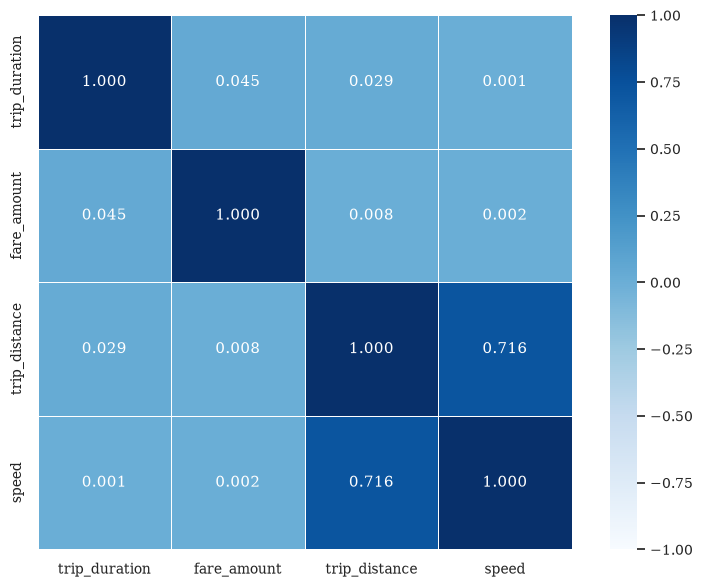

Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap.png'!


In [17]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory
con = duckdb.connect(database=':memory:')

print("Extracting derived variables (trip_duration, fare_amount, trip_distance, speed) from processed dataset...")

# 1. Query to derive trip_duration and speed on the fly without applying pre-filters
query = """
WITH derived AS (
    SELECT 
        trip_distance,
        fare_amount,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS speed
    FROM '../data/processed/*.parquet'
)
SELECT trip_duration, fare_amount, trip_distance, speed
FROM derived
"""

df_sample = con.execute(query).df()
con.close()

# 2. Compute the Pearson correlation matrix using Pandas
corr_matrix = df_sample[['trip_duration', 'fare_amount', 'trip_distance', 'speed']].corr()

print("\n--- Correlation Matrix Summary ---")
print(corr_matrix.to_string())

# 3. Generate a heatmap visualization for the correlation matrix
print("\nGenerating correlation matrix heatmap...")
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap="Blues", 
    cbar=True,
    square=True,
    linewidths=0.5,
    vmin=-1, 
    vmax=1
)

# plt.title('Correlation Matrix: Duration, Fare, Distance, and Speed')
plt.savefig('../reports/figures/correlation_matrix_heatmap.png', dpi=300)
plt.show()

print("Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap.png'!")

Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 500,000 sampled records. Generating pairwise scatter plot matrix...


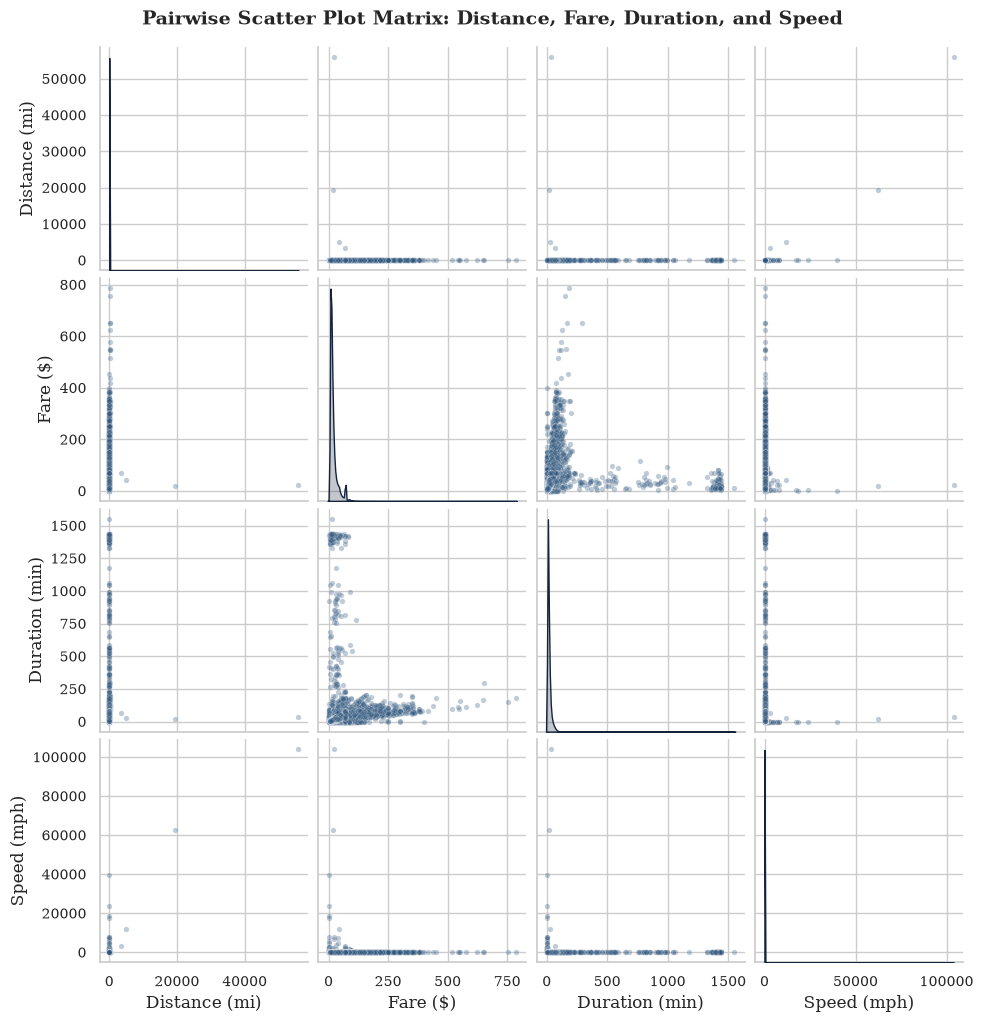

Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!


In [21]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory
con = duckdb.connect(database=':memory:')

print("Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...")

# Query to derive trip_duration and speed from processed parquet files
query = """
WITH derived AS (
    SELECT 
        trip_distance,
        fare_amount,
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS speed
    FROM '../data/processed/*.parquet'
)
SELECT trip_distance, fare_amount, trip_duration, speed
FROM derived
USING SAMPLE 500000;
"""

df_sample = con.execute(query).df()
con.close()

print(f"Loaded {len(df_sample):,} sampled records. Generating pairwise scatter plot matrix...")

# Rename columns for clean plot labels
df_sample.columns = ['Distance (mi)', 'Fare ($)', 'Duration (min)', 'Speed (mph)']

# Generate pairplot (scatter plots for every pair, KDE on diagonal)
g = sns.pairplot(
    df_sample, 
    kind='scatter', 
    diag_kind='kde',
    plot_kws={'alpha': 0.3, 's': 15, 'color': '#2D557D'},
    diag_kws={'color': '#14233C', 'fill': True}
)

g.fig.suptitle('Pairwise Scatter Plot Matrix: Distance, Fare, Duration, and Speed', y=1.02, fontsize=14, fontweight='bold')

plt.savefig('../reports/figures/pairwise_scatter_matrix.png', dpi=300)
plt.show()

print("Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!")